<a href="https://colab.research.google.com/github/oumaklaus/Deathon-ML-Internship/blob/main/Telco_Churn_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Data Loading


In [1]:
import urllib.request

base_url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
churn = "churn.csv"
urllib.request.urlretrieve(base_url, churn)


('churn.csv', <http.client.HTTPMessage at 0x7fb16c142850>)

In [2]:
!ls


churn.csv  sample_data


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, classification_report,confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
sns.set_theme(style = "whitegrid")


In [4]:
df = pd.read_csv("churn.csv")


# 2. EDA


In [5]:
df.shape


(7043, 21)

In [6]:
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.tail()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes
7042,3186-AJIEK,Male,0,No,No,66,Yes,No,Fiber optic,Yes,...,Yes,Yes,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.65,6844.5,No


In [8]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [9]:
df.describe()


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [10]:
df['Churn'].value_counts()


,count
Churn,
No,5174
Yes,1869


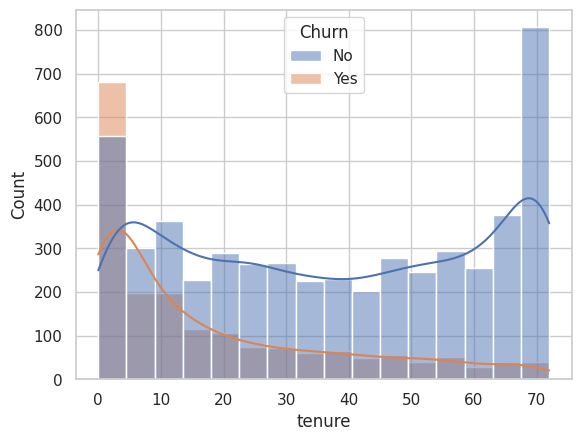

In [11]:
# TotalCharges is text until cleaning -> explore only numeric-typed features for now
sns.histplot(data=df, x = "tenure", hue="Churn", kde=True)
plt.show()


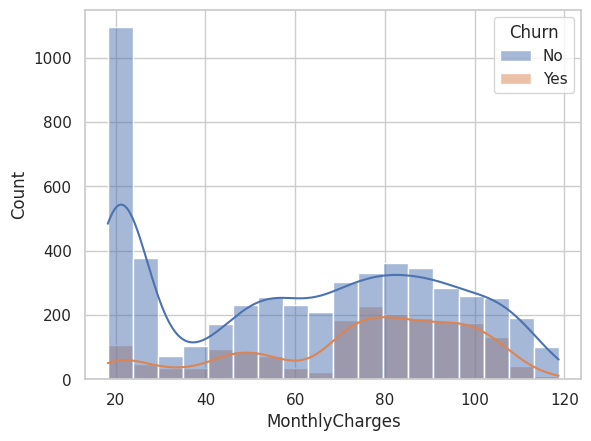

In [12]:
sns.histplot(data=df, x = "MonthlyCharges", hue="Churn", kde=True)
plt.show()


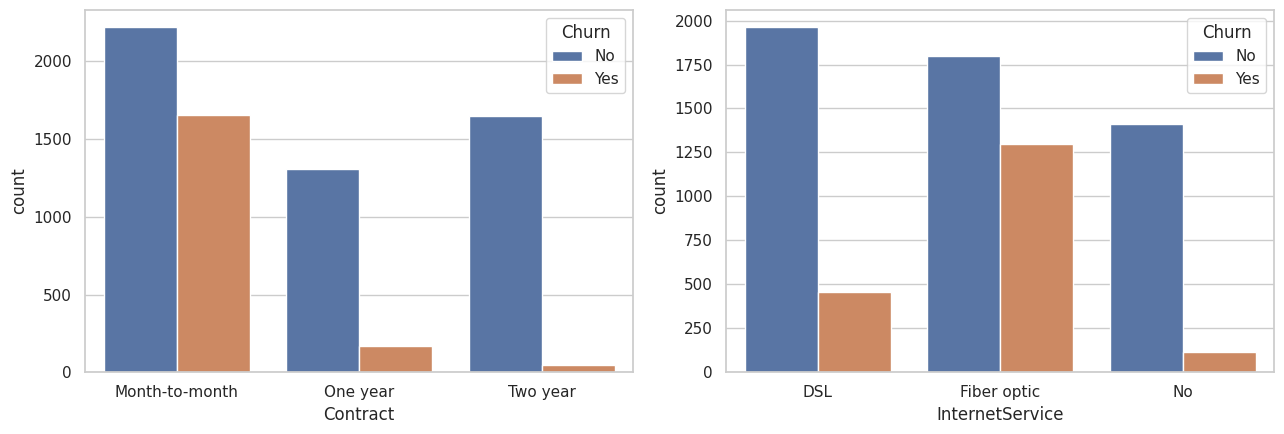

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=df, x = "Contract", hue="Churn", ax=axes[0])
sns.countplot(data=df, x = "InternetService", hue="Churn", ax=axes[1])
plt.tight_layout()
plt.show()


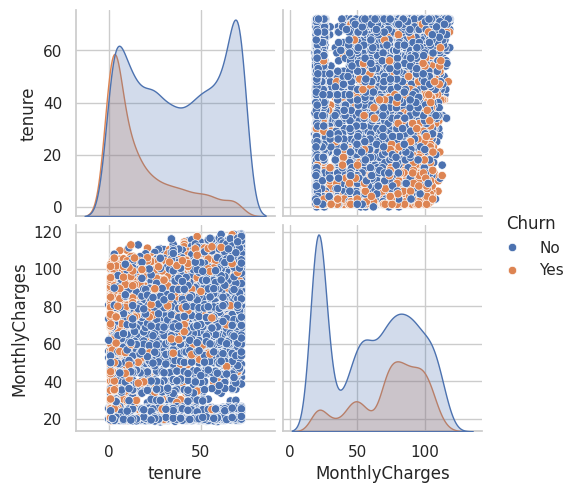

In [14]:
sns.pairplot(df, hue = "Churn", vars=["tenure", "MonthlyCharges"])


## 3. Data Cleaning


In [15]:
# TotalCharges is text with some empty strings -> convert and drop those rows
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df["TotalCharges"].isnull().sum(), "empty TotalCharges rows dropped")
df = df.dropna(subset=["TotalCharges"]).reset_index(drop=True)


11 empty TotalCharges rows dropped


In [16]:
# "No phone/internet service" -> "No" so categories stay consistent
no_service = ["MultipleLines", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
              "TechSupport", "StreamingTV", "StreamingMovies"]
for col in no_service:
    df[col] = df[col].replace({"No phone service": "No", "No internet service": "No"})

df = df.drop(columns = "customerID")
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7032 entries, 0 to 7031
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7032 non-null   object 
 1   SeniorCitizen     7032 non-null   int64  
 2   Partner           7032 non-null   object 
 3   Dependents        7032 non-null   object 
 4   tenure            7032 non-null   int64  
 5   PhoneService      7032 non-null   object 
 6   MultipleLines     7032 non-null   object 
 7   InternetService   7032 non-null   object 
 8   OnlineSecurity    7032 non-null   object 
 9   OnlineBackup      7032 non-null   object 
 10  DeviceProtection  7032 non-null   object 
 11  TechSupport       7032 non-null   object 
 12  StreamingTV       7032 non-null   object 
 13  StreamingMovies   7032 non-null   object 
 14  Contract          7032 non-null   object 
 15  PaperlessBilling  7032 non-null   object 
 16  PaymentMethod     7032 non-null   object 


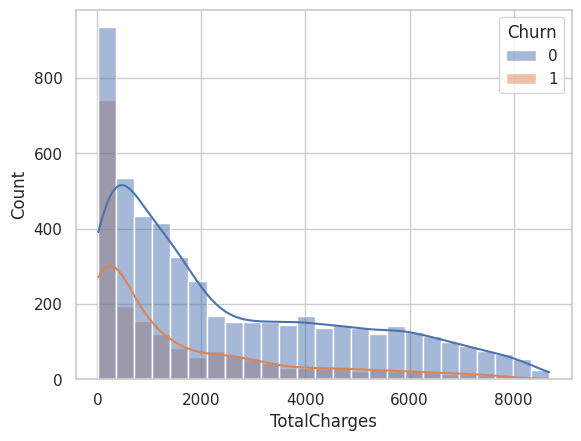

In [17]:
sns.histplot(data=df, x = "TotalCharges", hue="Churn", kde=True)
plt.show()


## 4. Dataset Splitting


In [18]:
X = df.drop(columns = "Churn")
y = df["Churn"]


In [19]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.2, random_state = RANDOM_STATE, stratify=y)


In [20]:
print("X Train: ", X_train.shape)


X Train:  (5625, 19)


In [21]:
print("X Test:  ", X_test.shape)


X Test:   (1407, 19)


## 5. Encoding & Feature Scaling


In [22]:
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(include=[object]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])


In [23]:
X_train_s = preprocessor.fit_transform(X_train)
X_test_s = preprocessor.transform(X_test)


## 6. Model Training


In [24]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)

log_reg.fit(X_train_s, y_train)
tree.fit(X_train_s, y_train)

pred_lr = log_reg.predict(X_test_s)
pred_tree = tree.predict(X_test_s)


## 7. Model Evaluation


In [25]:
print("Logistic Regression")
print(classification_report(y_test, pred_lr))

print("Decision Tree")
print(classification_report(y_test, pred_tree))


Logistic Regression
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407

Decision Tree
              precision    recall  f1-score   support

           0       0.80      0.93      0.86      1033
           1       0.66      0.35      0.46       374

    accuracy                           0.78      1407
   macro avg       0.73      0.64      0.66      1407
weighted avg       0.76      0.78      0.75      1407



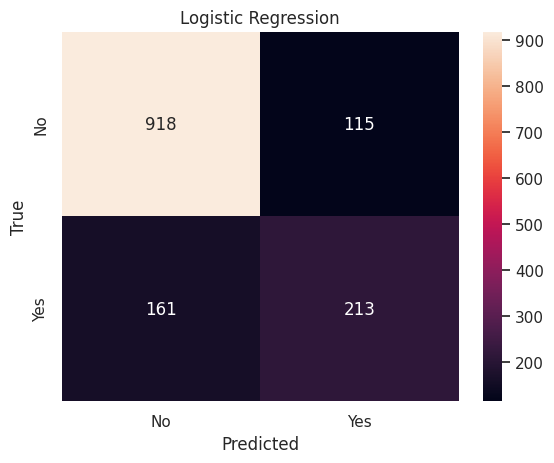

In [26]:
labels = ["No", "Yes"]

sns.heatmap(confusion_matrix(y_test, pred_lr), annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels)
plt.title("Logistic Regression")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


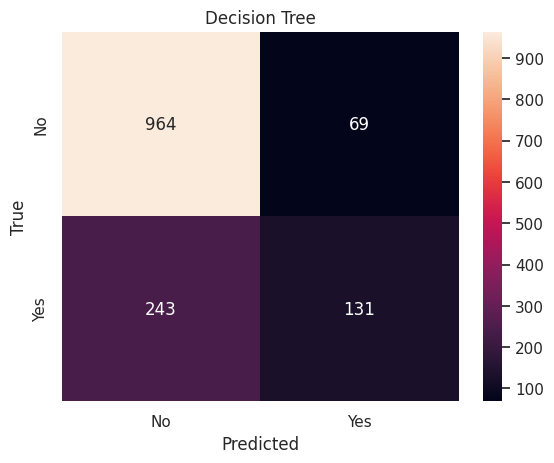

In [27]:
sns.heatmap(confusion_matrix(y_test, pred_tree), annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels)
plt.title("Decision Tree")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()


## 8. Decision Boundary Visualization


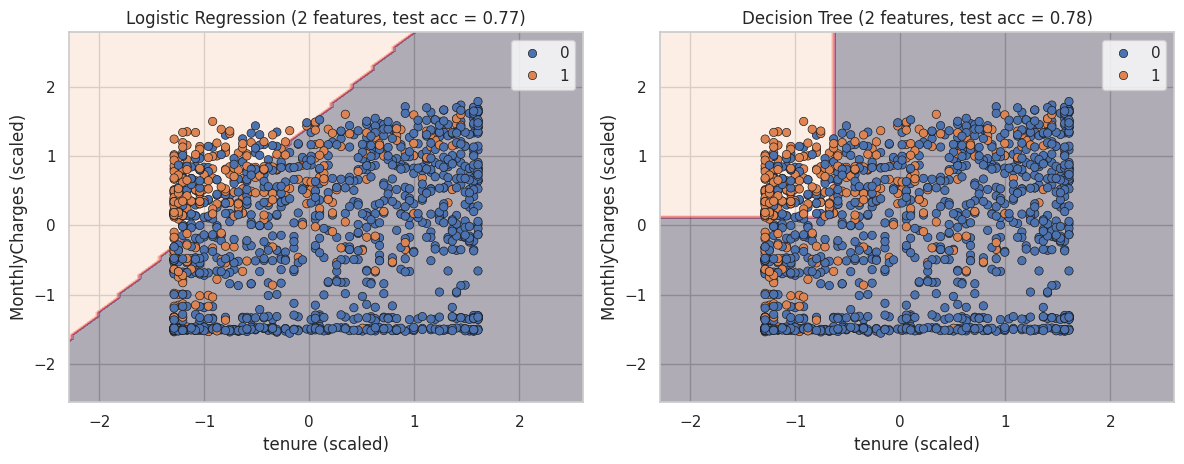

In [28]:
pair = ["tenure", "MonthlyCharges"]
sc2 = StandardScaler()
Xtr2 = sc2.fit_transform(X_train[pair])
Xte2 = sc2.transform(X_test[pair])

models_2d = {
    "Logistic Regression": LogisticRegression(max_iter=200, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, m) in zip(axes, models_2d.items()):
    m.fit(Xtr2, y_train)
    acc = accuracy_score(y_test, m.predict(Xte2))
    DecisionBoundaryDisplay.from_estimator(
        m, Xtr2, response_method="predict", alpha=0.35,
        xlabel="tenure (scaled)", ylabel="MonthlyCharges (scaled)", ax=ax)
    sns.scatterplot(x=Xte2[:, 0], y=Xte2[:, 1], hue=y_test.values, edgecolor="k", ax=ax)
    ax.set_title(f"{name} (2 features, test acc = {acc:.2f})")

plt.tight_layout()
plt.show()


## 9. Feature Importance


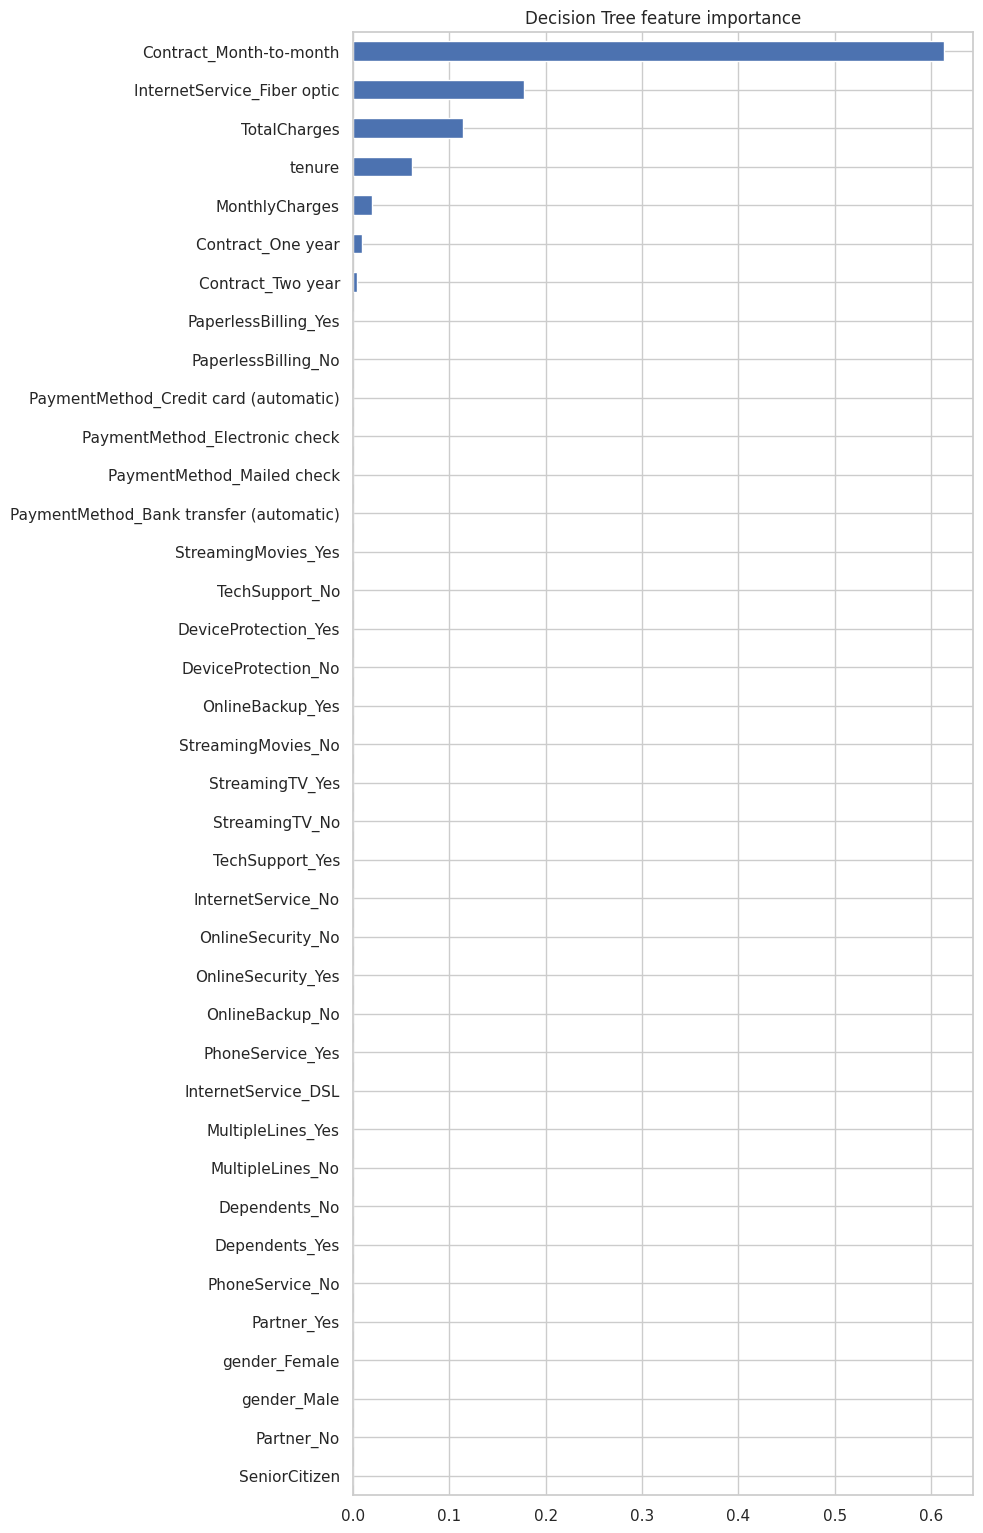

In [29]:
feature_names = num_cols + list(preprocessor.named_transformers_["cat"].get_feature_names_out())
imp = pd.Series(tree.feature_importances_, index=feature_names).sort_values()
imp.plot(kind="barh", title="Decision Tree feature importance", figsize=(8, len(imp)//2))
plt.show()
